# Convolutional Neural Networks

## Project: Write an Algorithm for Landmark Classification

### A simple app

In this notebook we build a very simple app that uses our exported model.

> <img src="static_images/icons/noun-info-2558213.png" alt="?" style="width:25px"/> Note how we are not importing anything from our source code (we do not use any module from the ``src`` directory). This is because the exported model, differently from the model weights, is a standalone serialization of our model and therefore it does not need anything else. You can ship that file to anybody, and as long as they can import ``torch``, they will be able to use your model. This is very important for releasing pytorch models to production.

### Test your app
Go to a search engine for images (like Google Images) and search for images of some of the landmarks, like the Eiffel Tower, the Golden Gate Bridge, Machu Picchu and so on. Save a few examples locally, then upload them to your app to see how your model behaves!

The app will show the top 5 classes that the model think are most relevant for the picture you have uploaded

In [1]:
from ipywidgets import VBox, Button, FileUpload, Output, Label
from PIL import Image
from IPython.display import display
import io
import numpy as np
import torchvision
import torchvision.transforms as T
import torch

# Decide which model you want to use among the ones exported
learn_inf = torch.jit.load("checkpoints/transfer_exported.pt")

def on_click_classify(change):

    # Load image that has been uploaded
    fn = io.BytesIO(btn_upload.data[-1])

    # convert to RGB so that PNGs with transparency or grayscale images also work
    img = Image.open(fn).convert("RGB")

    # Let's clear the previous output (if any)
    out_pl.clear_output()

    # Display the image
    with out_pl:

        ratio = img.size[0] / img.size[1]
        c = img.copy()
        c.thumbnail([ratio * 200, 200])
        display(c)

    # Transform to tensor
    timg = T.ToTensor()(img).unsqueeze_(0)

    # Calling the model
    softmax = learn_inf(timg).data.cpu().numpy().squeeze()
    
    # Get the indexes of the classes ordered by softmax
    # (larger first)
    idxs = np.argsort(softmax)[::-1]
    
    # Loop over the classes with the largest softmax
    for i in range(5):
        # Get softmax value
        p = softmax[idxs[i]]
    
        # Get class name
        landmark_name = learn_inf.class_names[idxs[i]]
        
        labels[i].value = f"{landmark_name} (prob: {p:.2f})"


# Putting back btn_upload to a widget for next cell
btn_upload = FileUpload()

btn_run = Button(description="Classify")
btn_run.on_click(on_click_classify)

labels = []
for _ in range(5):
    labels.append(Label())

out_pl = Output()
out_pl.clear_output()

wgs = [Label("Please upload a picture of a landmark"), btn_upload, btn_run, out_pl]
wgs.extend(labels)

VBox(wgs)

### Testing the app on new images

The upload widget above is interactive, so its state is not saved in the notebook. To keep a record of how the app behaves, the cell below runs **exactly the same steps** as `on_click_classify` (load image → `ToTensor` → exported model → top 5 classes by softmax) on three photos that are **not** part of the training or test sets. They were downloaded from Wikimedia Commons into `static_images/app_test/`; see the README there for sources and licenses.

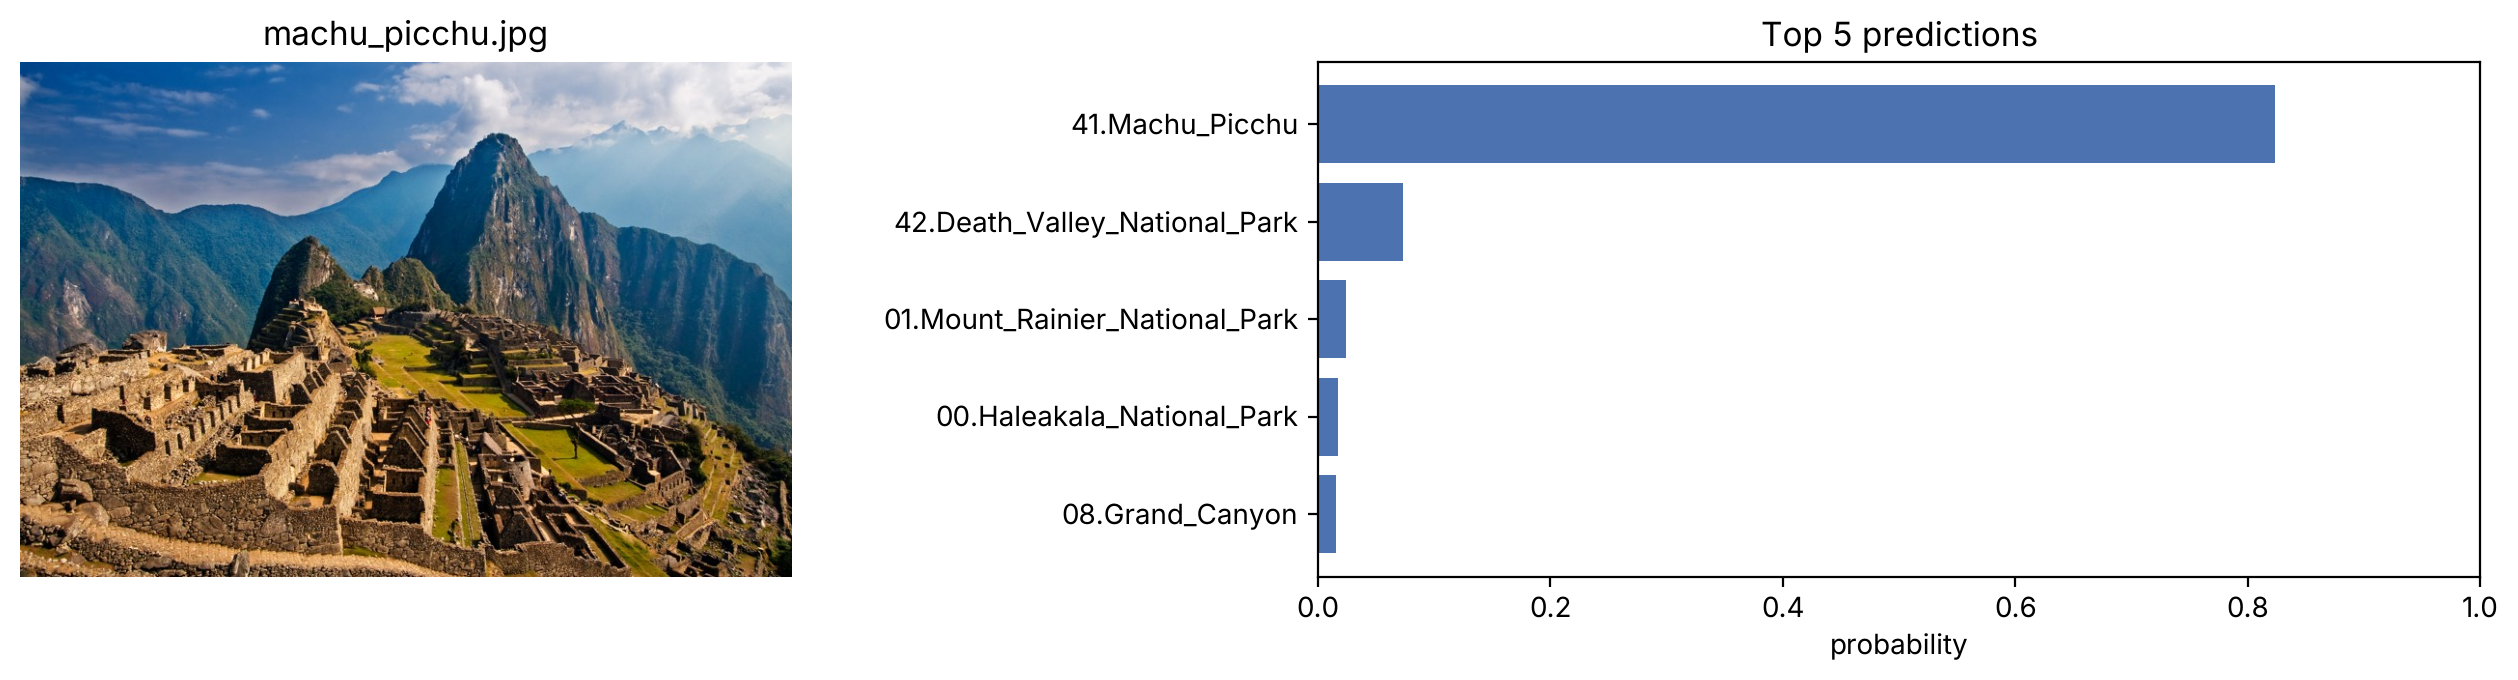

41.Machu_Picchu (prob: 0.82)
42.Death_Valley_National_Park (prob: 0.07)
01.Mount_Rainier_National_Park (prob: 0.02)
00.Haleakala_National_Park (prob: 0.02)
08.Grand_Canyon (prob: 0.02)


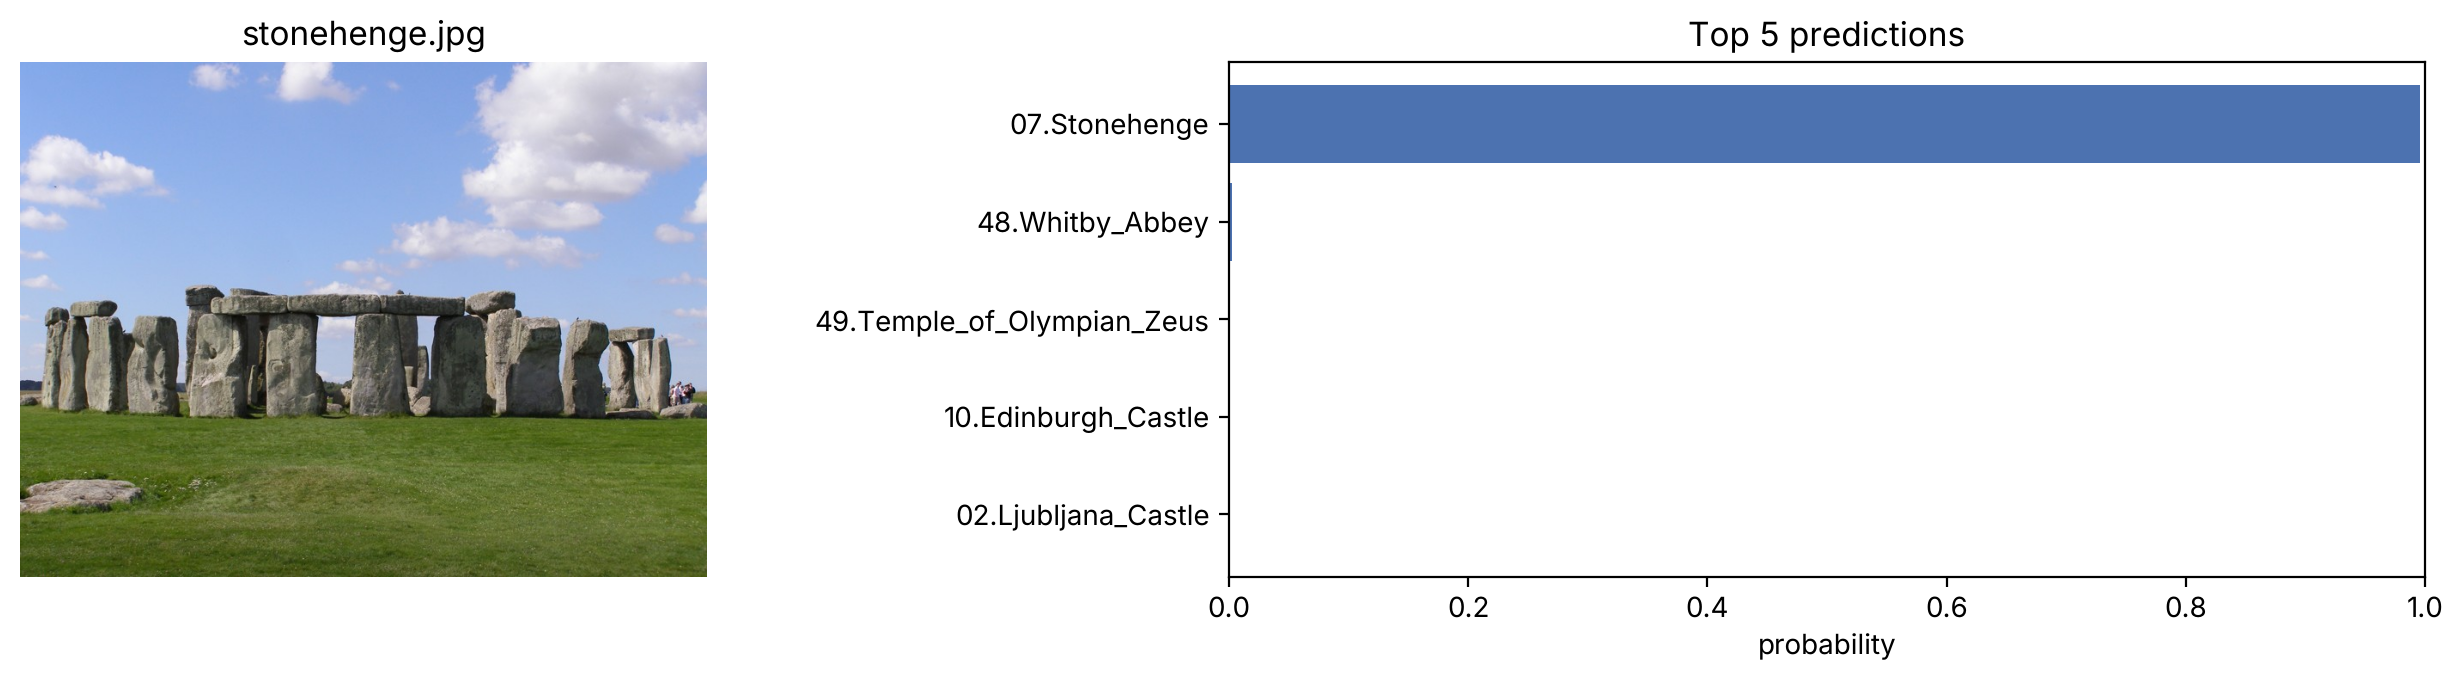

07.Stonehenge (prob: 1.00)
48.Whitby_Abbey (prob: 0.00)
49.Temple_of_Olympian_Zeus (prob: 0.00)
10.Edinburgh_Castle (prob: 0.00)
02.Ljubljana_Castle (prob: 0.00)


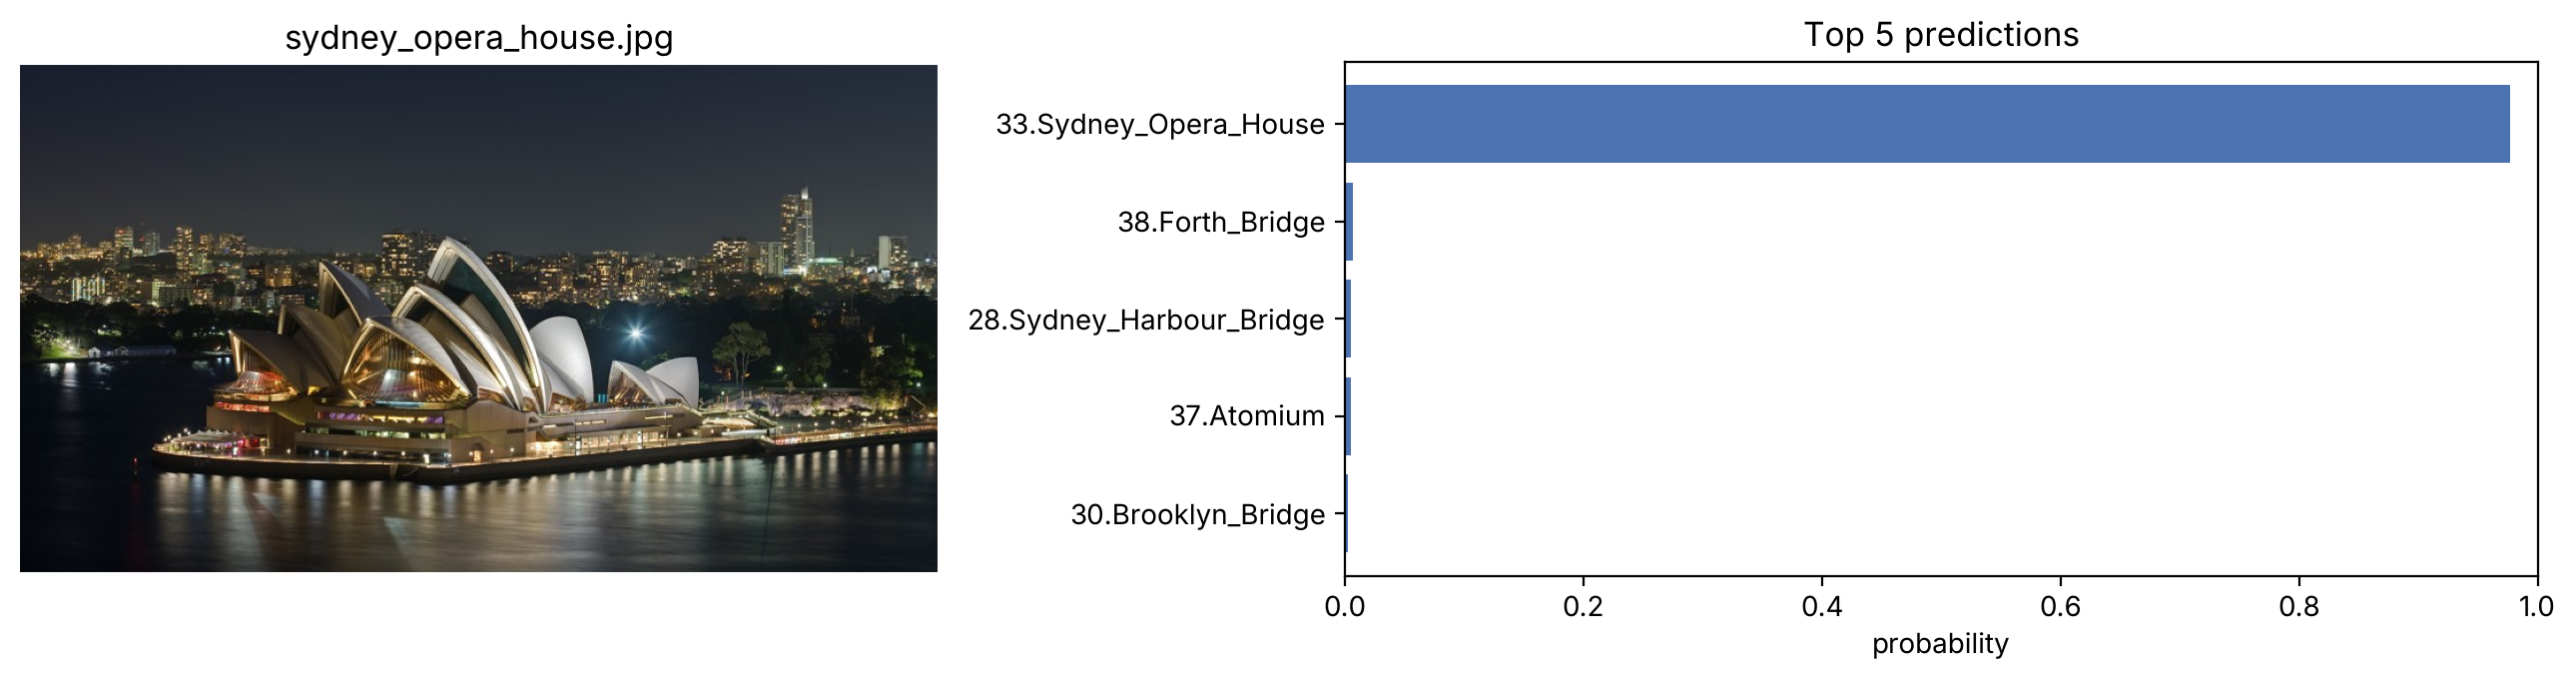

33.Sydney_Opera_House (prob: 0.98)
38.Forth_Bridge (prob: 0.01)
28.Sydney_Harbour_Bridge (prob: 0.00)
37.Atomium (prob: 0.00)
30.Brooklyn_Bridge (prob: 0.00)


In [2]:
import glob
import matplotlib.pyplot as plt


def top_k_landmarks(img, k=5):
    # Same steps as in on_click_classify
    timg = T.ToTensor()(img).unsqueeze_(0)
    softmax = learn_inf(timg).data.cpu().numpy().squeeze()
    idxs = np.argsort(softmax)[::-1][:k]
    return [(learn_inf.class_names[i], float(softmax[i])) for i in idxs]


for path in sorted(glob.glob("static_images/app_test/*.jpg")):
    img = Image.open(path).convert("RGB")
    preds = top_k_landmarks(img)

    fig, (ax_img, ax_bar) = plt.subplots(
        1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios": [1, 1.3]}
    )
    ax_img.imshow(img)
    ax_img.axis("off")
    ax_img.set_title(path.split("/")[-1])

    names = [name for name, _ in preds][::-1]
    probs = [prob for _, prob in preds][::-1]
    ax_bar.barh(names, probs, color="#4C72B0")
    ax_bar.set_xlim(0, 1)
    ax_bar.set_xlabel("probability")
    ax_bar.set_title("Top 5 predictions")
    plt.tight_layout()
    plt.show()

    for name, prob in preds:
        print(f"{name} (prob: {prob:.2f})")


## (optional) Standalone app or web app

You can run this notebook as a standalone app on your computer by following these steps:

1. Download this notebook in a directory on your machine
2. Download the model export (for example, ``checkpoints/transfer_exported.pt``) in a subdirectory called ``checkpoints`` within the directory where you save the app.ipynb notebook
3. Install voila if you don't have it already (``pip install voila``)
4. Run your app: ``voila app.ipynb --show_tracebacks=True``
5. Customize your notebook to make your app prettier and rerun voila

You can also deploy this app as a website using Binder: https://voila.readthedocs.io/en/stable/deploy.html#deployment-on-binder

# Create your submission archive

Now that you are done with your project, please run the following cell. It will generate a file containing all the code you have written, as well as the notebooks. Please submit that file to complete your project

In [3]:
!python src/create_submit_pkg.py

executing: jupyter nbconvert --to html app.ipynb


[NbConvertApp] Converting notebook app.ipynb to html


[NbConvertApp] Writing 300474 bytes to app.html


executing: jupyter nbconvert --to html cnn_from_scratch.ipynb


[NbConvertApp] Converting notebook cnn_from_scratch.ipynb to html


[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).


... (7 outputs left out)

transfer_learning.ipynb


app.html
cnn_from_scratch.html


transfer_learning.html



----------------------------------------------------------------
Done. Please submit the file submission_2026-11-23T12h33m.tar.gz
----------------------------------------------------------------
